# Contact distance analysis - 1YVL

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Load data

In [6]:
WT_dfs = []
for rep in range(1, 4):
    df = pd.read_csv(f'../../../data/1YVL_noNTD/WT/rep{rep}/analysis/004_contacts/pairs_full.csv')
    WT_dfs.append(df)

T385M_dfs = []
for rep in range(1, 4):
    df = pd.read_csv(f'../../../data/1YVL_noNTD/T385M/rep{rep}/analysis/004_contacts/pairs_full.csv')
    T385M_dfs.append(df)

In [7]:
WT_dfs[0].head()

,frame,sele1_resid,sele1_resnm,sele1_chain,sele2_resid,sele2_resnm,sele2_chain,distance
0,1000,21,MET,A,259,MET,B,4.757680
1,1000,21,MET,A,259,MET,B,4.963368
2,1000,21,MET,A,259,MET,B,4.634706
3,1000,21,MET,A,259,MET,B,4.040002
4,1000,21,MET,A,259,MET,B,4.697450


### Preprocessing

Adjust residue numbers.

In [8]:
offset = 133

In [11]:
def adjust_resid(dfs):
    for df in (dfs):
        df["sele1_resid_adj"] = df["sele1_resid"] + offset
        df["sele2_resid_adj"] = df["sele2_resid"] + offset

In [12]:
adjust_resid(WT_dfs)
adjust_resid(T385M_dfs)

In [13]:
WT_dfs[0].head()

,frame,sele1_resid,sele1_resnm,sele1_chain,sele2_resid,sele2_resnm,sele2_chain,distance,sele1_resid_adj,sele2_resid_adj
0,1000,21,MET,A,259,MET,B,4.757680,154,392
1,1000,21,MET,A,259,MET,B,4.963368,154,392
2,1000,21,MET,A,259,MET,B,4.634706,154,392
3,1000,21,MET,A,259,MET,B,4.040002,154,392
4,1000,21,MET,A,259,MET,B,4.697450,154,392


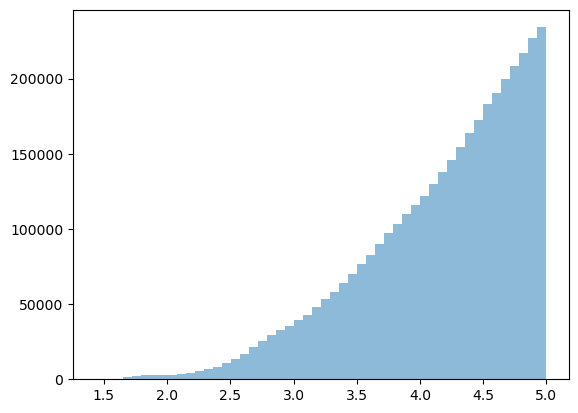

In [14]:
plt.hist(WT_dfs[0]['distance'], bins=50, alpha=0.5, label='wt', )
plt.show()

Note that each contact is associated with two residues, but no specific atoms. For this reason, a residue pair might be present multiple times in a single frame and, as seen next, dividing the count of a pair by the total number of frames might result in a value higher than 100. 

In [15]:
def aggregate_pairs(df_list):
    combined = pd.concat(df_list)
    
    agg_df = combined.groupby(['sele1_resnm', 'sele1_resid_adj', 'sele1_chain', 
                              'sele2_resnm', 'sele2_resid_adj', 'sele2_chain']).agg(
        count=('distance', 'size'), 
        distance_avg=('distance', 'mean') 
    ).reset_index()
    
    return agg_df

In [17]:
WT_agg = aggregate_pairs(WT_dfs)
T385M_agg = aggregate_pairs(T385M_dfs)

In [18]:
WT_agg.sort_values('distance_avg', ascending=True).head(10)

,sele1_resnm,sele1_resid_adj,sele1_chain,sele2_resnm,sele2_resid_adj,sele2_chain,count,distance_avg
105,ASP,168,A,LYS,388,B,61550,3.970831
444,LYS,388,A,ASP,168,B,66896,3.980326
26,ARG,405,A,ASP,165,B,105463,3.996491
200,GLU,164,A,ASN,391,B,28609,4.003055
204,GLU,164,A,LYS,388,B,122546,4.011923
197,GLU,157,A,TYR,356,B,95941,4.028339
563,TYR,356,A,GLU,157,B,62988,4.030078
161,GLN,352,A,GLN,275,B,101004,4.034415
490,MET,392,A,LYS,161,B,51170,4.048549
136,GLN,275,A,GLN,352,B,60042,4.049595


In [19]:
nframes = 1000

In [20]:
WT_agg["count_avg"] = WT_agg["count"] / (len(WT_dfs)* nframes)
T385M_agg["count_avg"] = T385M_agg["count"] / (len(T385M_dfs)* nframes)

In [21]:
WT_agg.sort_values('count_avg', ascending=False).head(10)

,sele1_resnm,sele1_resid_adj,sele1_chain,sele2_resnm,sele2_resid_adj,sele2_chain,count,distance_avg,count_avg
420,LYS,279,A,TYR,356,B,402445,4.154447,134.148333
573,TYR,356,A,LYS,279,B,317565,4.176377,105.855000
327,HIE,406,A,PHE,172,B,250222,4.163355,83.407333
211,GLU,169,A,HID,406,B,243356,4.143805,81.118667
358,LEU,383,A,LYS,175,B,232114,4.189568,77.371333
321,HIE,406,A,GLU,169,B,229343,4.155029,76.447667
133,GLN,275,A,ASN,355,B,224771,4.119485,74.923667
499,PHE,172,A,HID,406,B,211142,4.226141,70.380667
421,LYS,279,A,VAL,389,B,205802,4.167330,68.600667
405,LYS,278,A,ASN,357,B,190228,4.156486,63.409333


In [22]:
T385M_agg.sort_values('count_avg', ascending=False).head(10)

,sele1_resnm,sele1_resid_adj,sele1_chain,sele2_resnm,sele2_resid_adj,sele2_chain,count,distance_avg,count_avg
663,TYR,356,A,LYS,279,B,311378,4.156477,103.792667
173,GLN,275,A,TYR,356,B,265256,4.151354,88.418667
497,LYS,279,A,TYR,356,B,248381,4.165399,82.793667
498,LYS,279,A,VAL,389,B,245981,4.159789,81.993667
662,TYR,356,A,LYS,278,B,226428,4.198638,75.476000
250,GLU,169,A,HID,406,B,182653,4.135627,60.884333
593,PHE,172,A,HID,406,B,175456,4.221823,58.485333
648,TYR,356,A,GLN,275,B,171269,4.121448,57.089667
125,ASP,168,A,MET,385,B,157939,4.047449,52.646333
590,PHE,172,A,GLN,408,B,144209,4.094482,48.069667


### Comparison

In [23]:
def pivotdf_count_avg(df):
    pivot = df.pivot_table(values='count_avg', 
                          index='sele2_resid_adj', 
                          columns='sele1_resid_adj', 
                          aggfunc='mean')
    return pivot

In [52]:
WT_pivot = pivotdf_count_avg(WT_agg)
T385M_pivot = pivotdf_count_avg(T385M_agg)

In [25]:
WT_pivot.head()

sele1_resid_adj,147,150,153,154,155,156,157,158,160,161,...,419,439,440,441,442,443,444,654,658,659
sele2_resid_adj,,,,,,,,,,,,,,,,,,,,,
147,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
150,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
154,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
155,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
156,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [41]:
domains = [
    {"start": 134, "end": 317, "color": "blue",   "label": "CCD"},
    {"start": 318, "end": 488, "color": "red",    "label": "DBD"},
    {"start": 489, "end": 576, "color": "green",  "label": "LD"},
    {"start": 577, "end": 683, "color": "orange", "label": "SH2"},
]

In [38]:
def residue_color(res):
    for r in domains:
        if r["start"] <= res <= r["end"]:
            return r["color"]
    return "black"

In [49]:
WT_agg[WT_agg['sele1_resid_adj'] == 658]

,sele1_resnm,sele1_resid_adj,sele1_chain,sele2_resnm,sele2_resid_adj,sele2_chain,count,distance_avg,count_avg
93,ASN,658,A,ASN,658,B,23,4.351889,0.007667
94,ASN,658,A,ILE,659,B,14,4.530374,0.004667


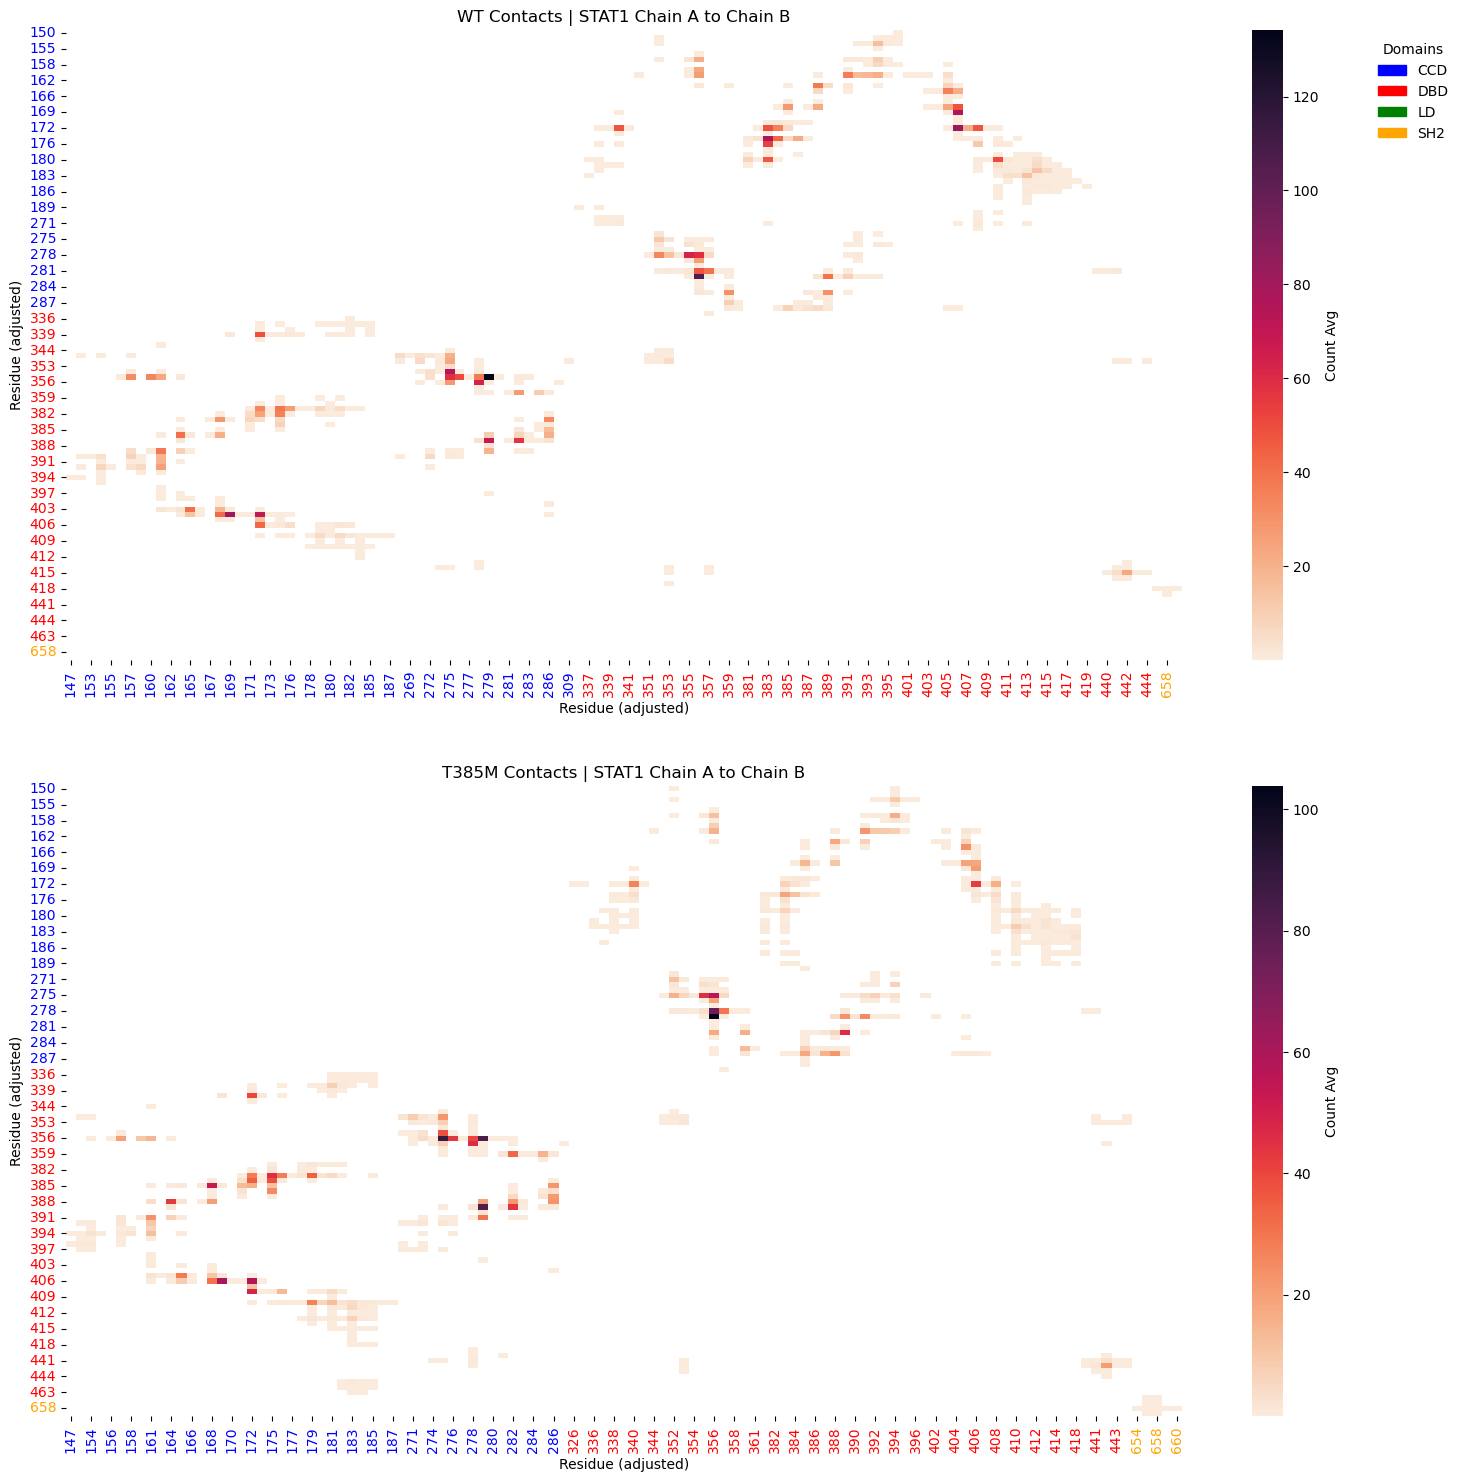

In [53]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(18, 18), sharey=True)
sns.heatmap(WT_pivot, cmap="rocket_r", ax=ax1, cbar_kws={"label": "Count Avg"})
ax1.set_title('WT Contacts | STAT1 Chain A to Chain B')
ax1.set_xlabel("Residue (adjusted)")
ax1.set_ylabel("Residue (adjusted)")
sns.heatmap(T385M_pivot, cmap='rocket_r', ax=ax2, cbar_kws={'label': 'Count Avg'})
ax2.set_title('T385M Contacts | STAT1 Chain A to Chain B')
ax2.set_xlabel("Residue (adjusted)")
ax2.set_ylabel("Residue (adjusted)")
for tick in ax1.get_xticklabels() + ax2.get_xticklabels():
    try:
        res = int(tick.get_text())
        tick.set_color(residue_color(res))
    except ValueError:
        pass  # non-numeric labels
for tick in ax1.get_yticklabels() + ax2.get_yticklabels():
    try:
        res = int(tick.get_text())
        tick.set_color(residue_color(res))
    except ValueError:
        pass
from matplotlib.patches import Patch

legend_patches = [
    Patch(color=r["color"], label=r["label"]) for r in domains
]

ax1.legend(
    handles=legend_patches,
    title="Domains",
    loc="upper right",
    bbox_to_anchor=(1.25, 1),
    frameon=False
)



In [ ]:
diff_pivot = WT_pivot - T385M_pivot

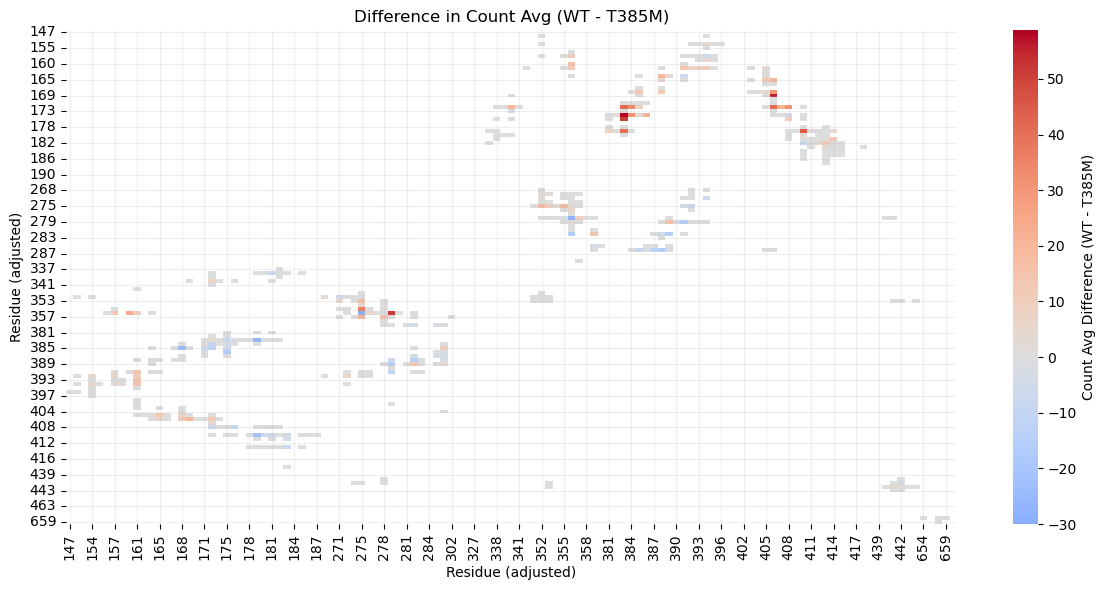

In [ ]:
plt.figure(figsize=(12, 6))

sns.heatmap(diff_pivot, cmap='coolwarm', center=0, cbar_kws={'label': 'Count Avg Difference (WT - T385M)'})
plt.title('Difference in Count Avg (WT - T385M)')
plt.xlabel('Residue (adjusted)')
plt.ylabel('Residue (adjusted)')

plt.grid(alpha = 0.2)
plt.tight_layout()
plt.show()

In [58]:
diff_pivot.head()

sele1_resid_adj,147,150,153,154,155,156,157,158,160,161,...,440,441,442,443,444,654,657,658,659,660
sele2_resid_adj,,,,,,,,,,,,,,,,,,,,,
147,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
150,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
153,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
154,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
155,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [67]:
diff_pivot.shape

(125, 119)

In [61]:
mask_rows = (diff_pivot.abs() >= 10).any(axis=1)
mask_cols = (diff_pivot.abs() >= 10).any(axis=0)

diff_pivot_filtered = diff_pivot.loc[mask_rows, mask_cols]

In [68]:
diff_pivot_filtered.head()

sele1_resid_adj,157,160,161,165,168,169,172,175,179,275,...,389,391,394,405,406,407,408,410,413,414
sele2_resid_adj,,,,,,,,,,,,,,,,,,,,,
160,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,-0.027000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
161,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,14.255333,12.625667,2.553000,NaN,NaN,NaN,NaN,NaN,NaN
164,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,4.359,-6.012333,NaN,1.470667,NaN,NaN,NaN,NaN,NaN,NaN
165,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,-0.008333,NaN,11.361667,19.931667,NaN,NaN,NaN,NaN,NaN
168,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,4.680667,29.971667,NaN,NaN,NaN,NaN,NaN


In [66]:
diff_pivot_filtered.shape

(33, 35)

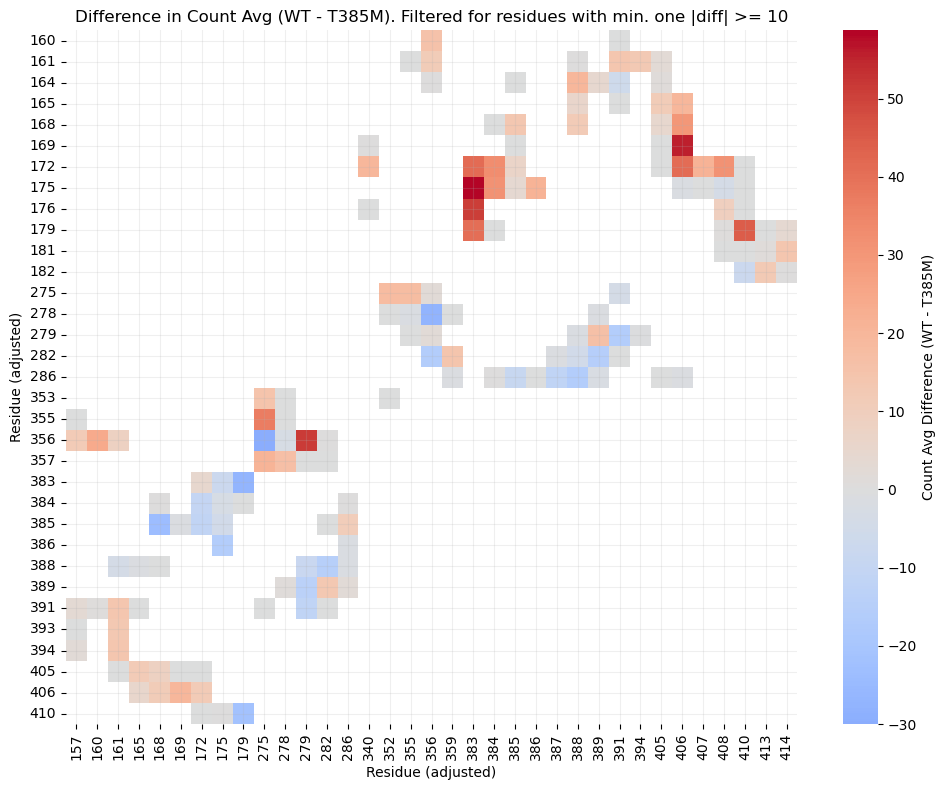

In [79]:
plt.figure(figsize=(10, 8))

sns.heatmap(diff_pivot_filtered, cmap='coolwarm', center=0, cbar_kws={'label': 'Count Avg Difference (WT - T385M)'})
plt.title('Difference in Count Avg (WT - T385M). Filtered for residues with min. one |diff| >= 10')
plt.xlabel('Residue (adjusted)')
plt.ylabel('Residue (adjusted)')

plt.grid(alpha = 0.2)
plt.tight_layout()
plt.show()

#### By average distance

In [80]:
def pivotdf_distance_avg(df):
    pivot = df.pivot_table(values='distance_avg', 
                          index='sele2_resid_adj', 
                          columns='sele1_resid_adj', 
                          aggfunc='mean')
    return pivot

In [82]:
WT_avg_pivot = pivotdf_distance_avg(WT_agg)
T385M_avg_pivot = pivotdf_distance_avg(T385M_agg)

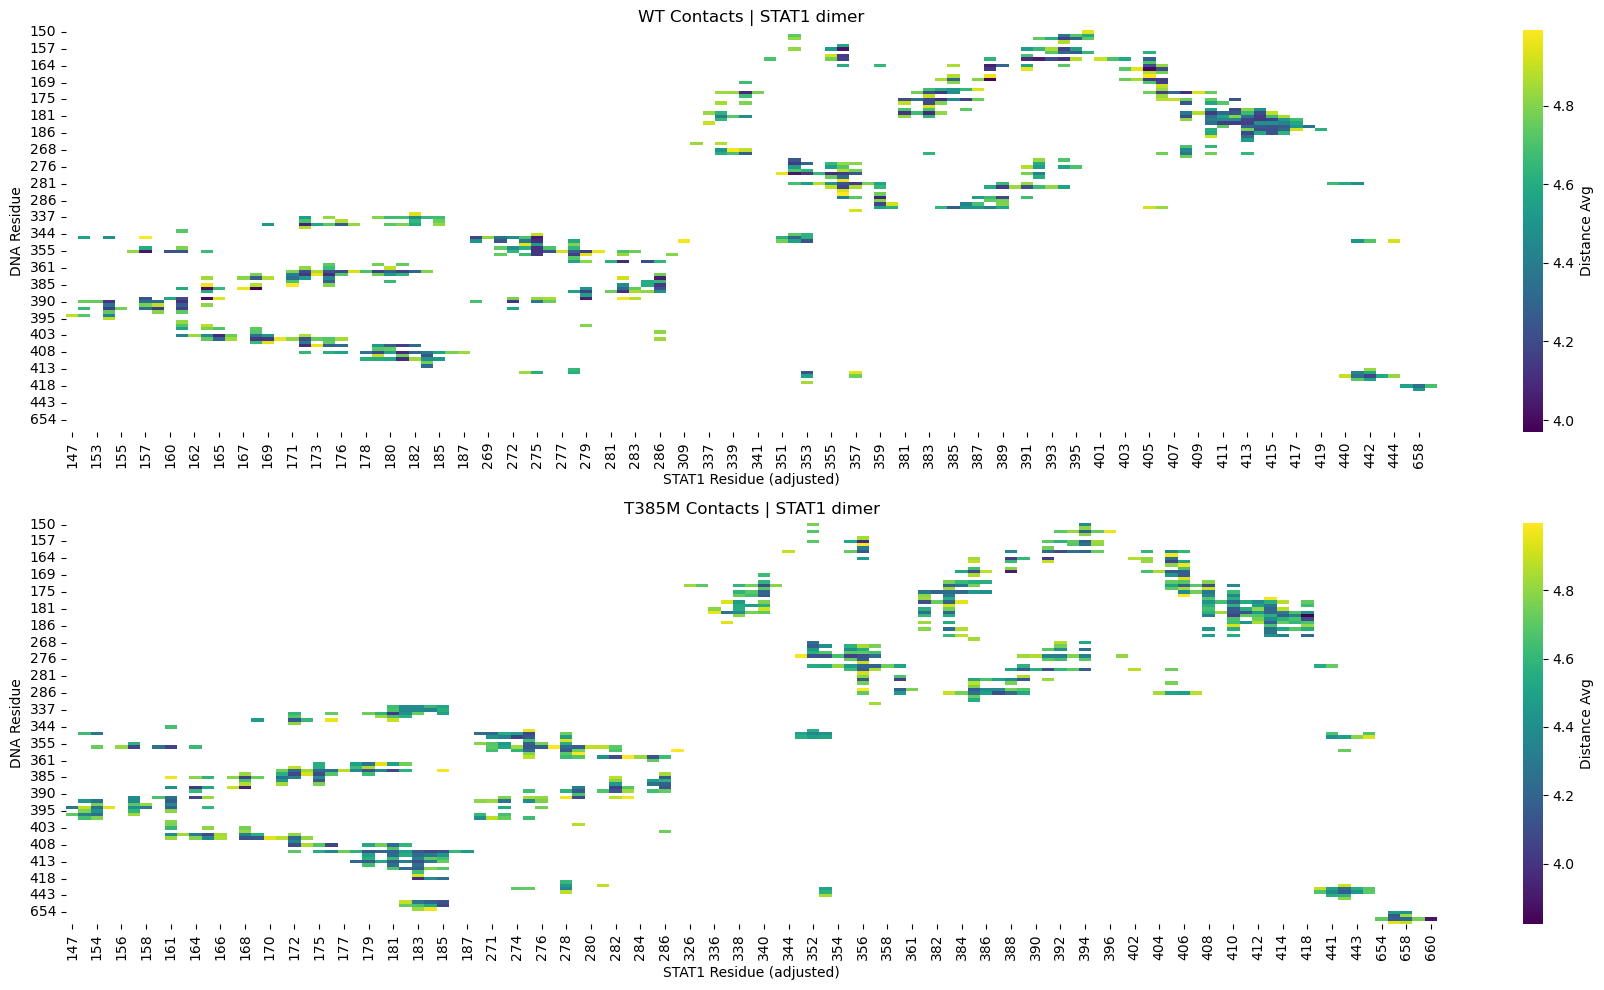

In [83]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(18, 10), sharey=True)

# WT heatmap
sns.heatmap(WT_avg_pivot, cmap='viridis', ax=ax1, cbar_kws={'label': 'Distance Avg'})
ax1.set_title('WT Contacts | STAT1 dimer')
ax1.set_xlabel('STAT1 Residue (adjusted)')
ax1.set_ylabel('DNA Residue')

# T385M heatmap
sns.heatmap(T385M_avg_pivot, cmap='viridis', ax=ax2, cbar_kws={'label': 'Distance Avg'})
ax2.set_title('T385M Contacts | STAT1 dimer')
ax2.set_xlabel('STAT1 Residue (adjusted)')
ax2.set_ylabel('DNA Residue')

plt.tight_layout()
plt.show()

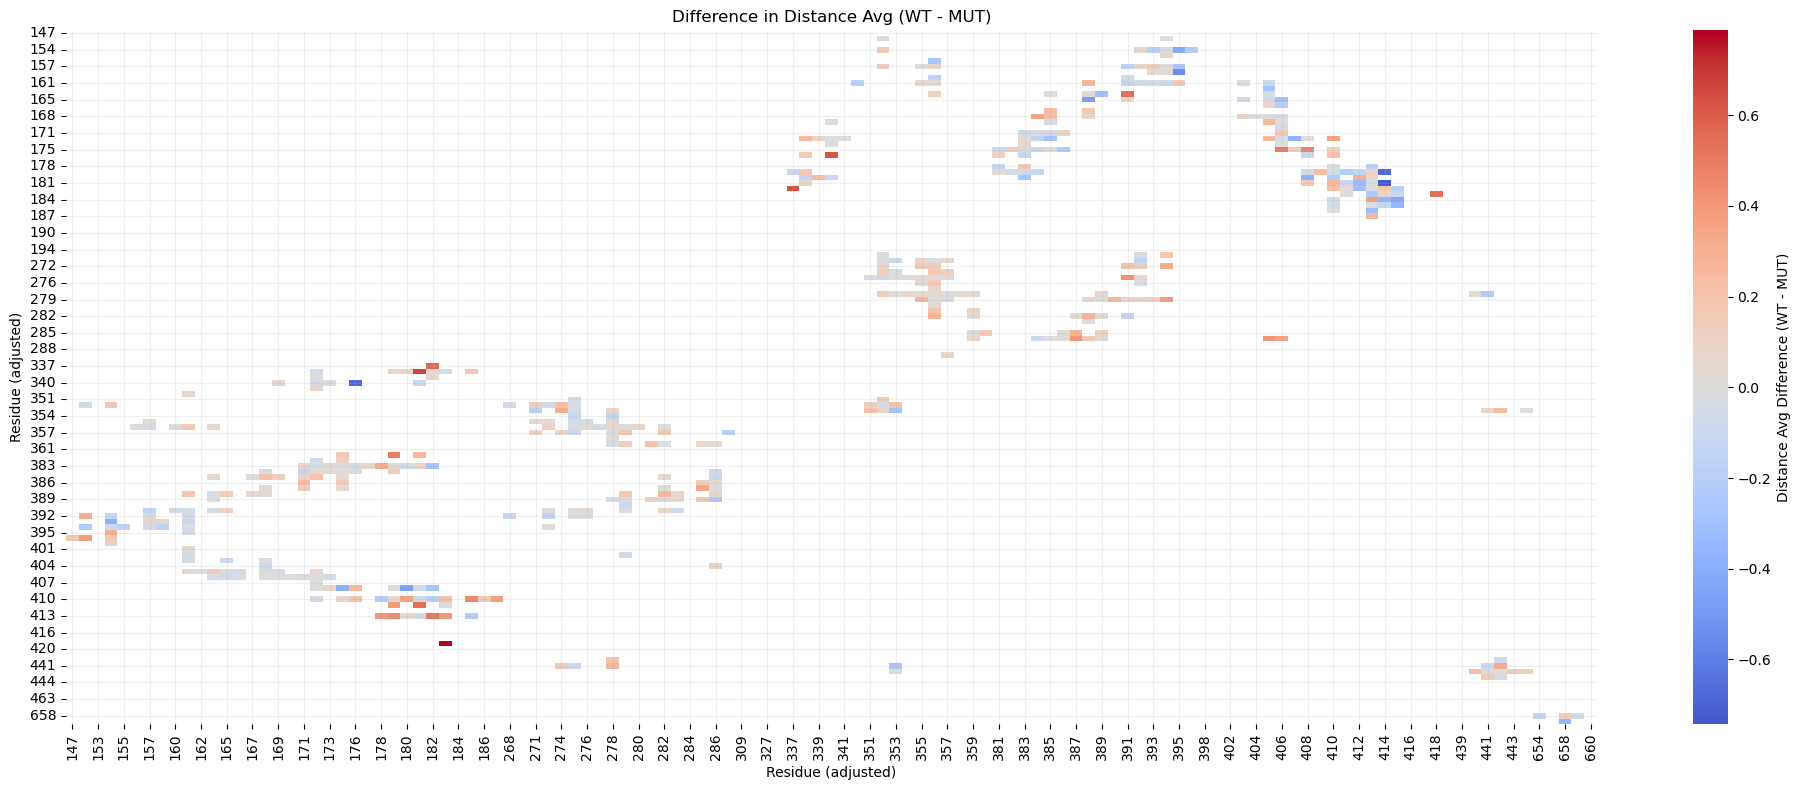

In [84]:
diff_avg_pivot = WT_avg_pivot - T385M_avg_pivot

plt.figure(figsize=(20, 8))

sns.heatmap(diff_avg_pivot, cmap='coolwarm', center=0, cbar_kws={'label': 'Distance Avg Difference (WT - MUT)'})
plt.title('Difference in Distance Avg (WT - MUT)')
plt.xlabel('Residue (adjusted)')
plt.ylabel('Residue (adjusted)')

plt.grid(alpha = 0.2)
plt.tight_layout()
plt.show()

In [85]:
mask_rows_avg = (diff_avg_pivot.abs() >= 0.4).any(axis=1)
mask_cols_avg = (diff_avg_pivot.abs() >= 0.4).any(axis=0)

diff_avg_pivot_filtered = diff_avg_pivot.loc[mask_rows_avg, mask_cols_avg]

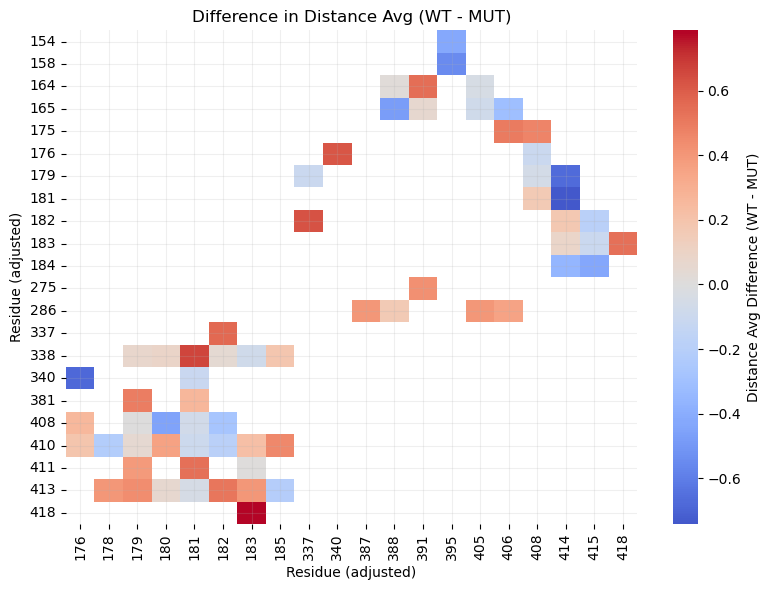

In [92]:
plt.figure(figsize=(8, 6))

sns.heatmap(diff_avg_pivot_filtered, cmap='coolwarm', center=0, cbar_kws={'label': 'Distance Avg Difference (WT - MUT)'})
plt.title('Difference in Distance Avg (WT - MUT)')
plt.xlabel('Residue (adjusted)')
plt.ylabel('Residue (adjusted)')

plt.grid(alpha = 0.2)
plt.tight_layout()
plt.show()

#### Statistical significance (Mann-Whitney U)

In [93]:
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
from statsmodels.tsa.stattools import acf
import os

In [96]:
WT_data = pd.concat(WT_dfs, ignore_index=True)
T385M_data = pd.concat(T385M_dfs, ignore_index=True)

In [95]:
# Define residue pair identifier
def create_pair_id(row):
    return f"{row['sele1_resid']}_{row['sele1_chain']}-{row['sele2_resid']}_{row['sele2_chain']}"

Mann-Whitney U test

In [97]:
WT_data['pair_id'] = WT_data.apply(create_pair_id, axis=1)
T385M_data['pair_id'] = T385M_data.apply(create_pair_id, axis=1)

# Get unique residue pairs present in either condition
all_pairs = set(WT_data['pair_id']).union(set(T385M_data['pair_id']))

# Store results
results = []

# Perform Mann-Whitney U test for each residue pair
for pair in all_pairs:
    # Extract distances for this pair in each condition
    dist_wt = WT_data[WT_data['pair_id'] == pair]['distance'].values
    dist_T419R = T385M_data[T385M_data['pair_id'] == pair]['distance'].values
    
    # Skip if either condition has no data or insufficient data
    if len(dist_wt) < 2 or len(dist_T419R) < 2:
        continue
    
    # Perform Mann-Whitney U test
    stat, p_value = mannwhitneyu(dist_wt, dist_T419R, alternative='two-sided')
    
    # Store result
    sele1, sele2 = pair.split('-')
    sele1_resid, sele1_chain = sele1.split('_')
    sele2_resid, sele2_chain = sele2.split('_')
    results.append({
        'pair': pair,
        'sele1': sele1,
        'sele2': sele2,
        'sele1_resid': int(sele1_resid) + 135,
        'sele1_chain': sele1_chain,
        'sele2_resid': int(sele2_resid),
        'sele2_chain': sele2_chain,
        'u_statistic': stat,
        'p_value': p_value,
        'n_cond1': len(dist_wt),
        'n_cond2': len(dist_T419R)
    })

# Convert results to dataframe
mannwhitney_df = pd.DataFrame(results)

In [98]:
mannwhitney_df[['pair', 'n_cond1', 'n_cond2']].sort_values(['n_cond1', 'n_cond2'], ascending=False).head(10)

,pair,n_cond1,n_cond2
87,146_A-223_B,402445,248381
184,223_A-146_B,317565,311378
124,273_A-39_B,250222,127069
30,36_A-273_B,243356,182653
82,250_A-42_B,232114,55899
312,273_A-36_B,229343,62423
382,142_A-222_B,224771,114204
93,39_A-273_B,211142,175456
216,146_A-256_B,205802,245981
182,145_A-224_B,190228,139225


Check ACF correlation score between timeframes

In [99]:
# Parameters
lags = 50  # Maximum lags for ACF computation
acf_threshold = 0.1  # Threshold for significant autocorrelation
output_dir = "acf_analysis"
os.makedirs(output_dir, exist_ok=True)

# Get unique residue pairs
unique_pairs = WT_data['pair_id'].unique()

# Initialize results list
results_acf = []

# Compute ACF metrics for each pair
for pair_id in unique_pairs:
    # Extract distance data
    pair_data = WT_data[WT_data['pair_id'] == pair_id]['distance'].dropna()
    
    # Skip if insufficient data
    if len(pair_data) < 2:
        print(f"Skipping pair {pair_id}: insufficient data ({len(pair_data)} points)")
        continue
    
    # Compute ACF
    try:
        acf_values = acf(pair_data, nlags=min(lags, len(pair_data)-1), fft=True)
    except Exception as e:
        print(f"Error computing ACF for pair {pair_id}: {e}")
        continue
    
    # Metric 1: Lag where ACF drops below threshold
    significant_lags = np.where(np.abs(acf_values) < acf_threshold)[0]
    lag_to_threshold = significant_lags[0] if len(significant_lags) > 0 else len(acf_values)
    
    # Metric 2: Sum of absolute ACF values (excluding lag 0)
    sum_abs_acf = np.sum(np.abs(acf_values[1:]))  # Skip lag 0 (always 1)
    
    # Metric 3: Effective sample size
    # n_eff = n / (1 + 2 * sum(ACF_k for k=1 to infinity))
    sum_acf = np.sum(acf_values[1:])  # Sum positive ACF for approximation
    n = len(pair_data)
    n_eff = n / (1 + 2 * sum_acf) if (1 + 2 * sum_acf) > 0 else n
    
    # Store results
    results_acf.append({
        'pair_id': pair_id,
        'n_points': n,
        'lag_to_threshold': lag_to_threshold,
        'sum_abs_acf': sum_abs_acf,
        'n_eff': n_eff
    })

# Create results dataframe
results_acf_df = pd.DataFrame(results_acf)


Skipping pair 255_A-34_B: insufficient data (1 points)
Skipping pair 263_A-14_B: insufficient data (1 points)
Skipping pair 24_A-219_B: insufficient data (1 points)
Skipping pair 258_A-32_B: insufficient data (1 points)
Skipping pair 14_A-263_B: insufficient data (1 points)
Skipping pair 271_A-32_B: insufficient data (1 points)
Skipping pair 40_A-275_B: insufficient data (1 points)
Skipping pair 223_A-23_B: insufficient data (1 points)
Skipping pair 36_A-274_B: insufficient data (1 points)
Skipping pair 249_A-39_B: insufficient data (1 points)
Skipping pair 274_A-42_B: insufficient data (1 points)
Skipping pair 259_A-143_B: insufficient data (1 points)
Skipping pair 207_A-58_B: insufficient data (1 points)
Skipping pair 203_A-56_B: insufficient data (1 points)
Skipping pair 205_A-56_B: insufficient data (1 points)
Skipping pair 21_A-264_B: insufficient data (1 points)
Skipping pair 141_A-221_B: insufficient data (1 points)
Skipping pair 176_A-220_B: insufficient data (1 points)
Skippin

In [100]:
results_acf_df.head()

,pair_id,n_points,lag_to_threshold,sum_abs_acf,n_eff
0,21_A-259_B,11471,2,1.429899,3070.167831
1,21_A-261_B,21432,3,2.375827,4041.612539
2,24_A-223_B,95941,2,3.338288,78542.114452
3,24_A-259_B,25304,14,4.817853,2379.155501
4,24_A-258_B,14676,2,5.196618,2058.481980


In [101]:

# Sort by lag_to_threshold (descending) to highlight pairs with persistent correlation
results_acf_df = results_acf_df.sort_values('lag_to_threshold', ascending=False)

# Save results to CSV
results_acf_df.to_csv(os.path.join(output_dir, 'acf_metrics.csv'), index=False)


In [102]:
# Summary statistics
print(f"Analyzed {len(results_acf_df)} residue pairs.")
print(f"Mean lag to threshold (ACF < {acf_threshold}): {results_acf_df['lag_to_threshold'].mean():.2f}")
print(f"Max lag to threshold: {results_acf_df['lag_to_threshold'].max()}")
print(f"Pairs with lag_to_threshold > 10: {len(results_acf_df[results_acf_df['lag_to_threshold'] > 10])}")
print(f"Results saved to '{output_dir}/acf_metrics.csv'")

Analyzed 544 residue pairs.
Mean lag to threshold (ACF < 0.1): 3.33
Max lag to threshold: 51
Pairs with lag_to_threshold > 10: 21
Results saved to 'acf_analysis/acf_metrics.csv'


In [103]:
results_acf_df[results_acf_df['lag_to_threshold'] > 10].sort_values('lag_to_threshold', ascending=False)

,pair_id,n_points,lag_to_threshold,sum_abs_acf,n_eff
82,223_A-139_B,3665,51,8.023097,215.004008
150,138_A-219_B,12343,51,7.326286,788.560494
185,253_A-153_B,3217,51,9.054975,168.341622
154,223_A-149_B,5673,51,8.098895,329.867955
100,254_A-153_B,10777,20,6.025065,825.815561
207,259_A-142_B,2806,20,6.815976,191.772077
144,31_A-272_B,8193,20,6.189150,612.409668
140,309_A-308_B,388,19,5.159717,34.899275
39,141_A-224_B,1463,16,5.035502,134.543762
236,259_A-139_B,229,16,6.594110,43.576735


In [104]:
# Adjust p-values for multiple testing
# Bonferroni
mannwhitney_df['p_adjusted_bonferroni'] = multipletests(mannwhitney_df['p_value'], method='bonferroni')[1]
# Benjamini-Hochberg
mannwhitney_df['p_adjusted_bh'] = multipletests(mannwhitney_df['p_value'], method='fdr_bh')[1]

In [105]:
mannwhitney_df.head()

,pair,sele1,sele2,sele1_resid,sele1_chain,sele2_resid,sele2_chain,u_statistic,p_value,n_cond1,n_cond2,p_adjusted_bonferroni,p_adjusted_bh
0,148_A-226_B,148_A,226_B,283,A,226,B,1.359865e+06,1.221236e-13,443,5065,5.324589e-11,4.033779e-13
1,272_A-35_B,272_A,35_B,407,A,35,B,2.035495e+09,1.291772e-03,71543,57501,5.632125e-01,2.525617e-03
2,259_A-139_B,259_A,139_B,394,A,139,B,2.381200e+04,3.568247e-03,229,178,1.000000e+00,6.592186e-03
3,138_A-224_B,138_A,224_B,273,A,224,B,3.213000e+04,1.344531e-03,161,339,5.862156e-01,2.605403e-03
4,277_A-47_B,277_A,47_B,412,A,47,B,8.707000e+05,1.608496e-07,12843,176,7.013043e-05,4.224725e-07


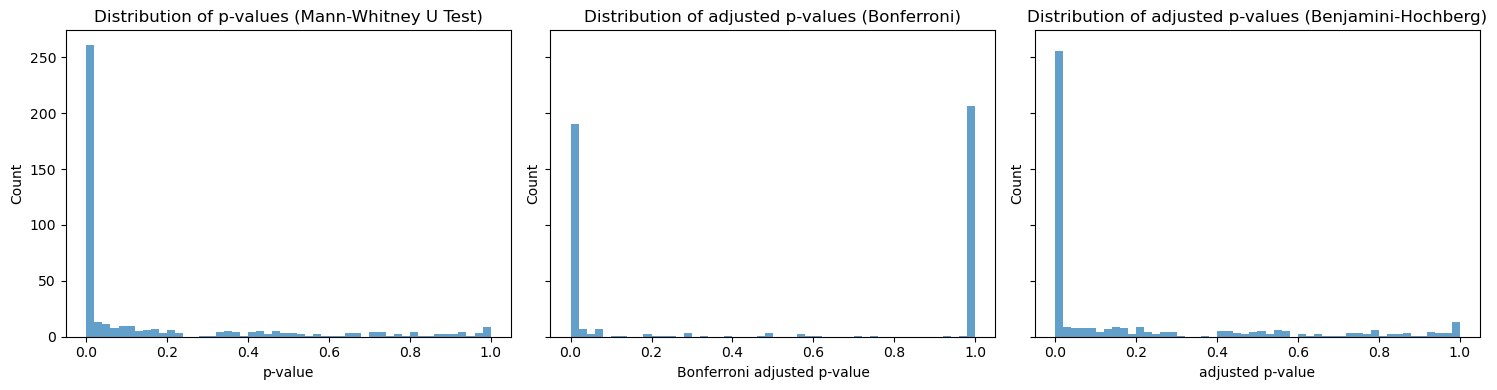

In [106]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

ax1.hist(mannwhitney_df['p_value'], bins=50, alpha=0.7)
ax1.set_xlabel('p-value')
ax1.set_ylabel('Count')
ax1.set_title('Distribution of p-values (Mann-Whitney U Test)')

ax2.hist(mannwhitney_df['p_adjusted_bonferroni'], bins=50, alpha=0.7)
ax2.set_xlabel('Bonferroni adjusted p-value')
ax2.set_ylabel('Count')
ax2.set_title('Distribution of adjusted p-values (Bonferroni)')

ax3.hist(mannwhitney_df['p_adjusted_bh'], bins=50, alpha=0.7)
ax3.set_xlabel('adjusted p-value')
ax3.set_ylabel('Count')
ax3.set_title('Distribution of adjusted p-values (Benjamini-Hochberg)')

plt.tight_layout()
plt.show()

Further analysis will use the Benjamini-Hochberg adjusted p-values. This method controls the false discovery rate (FDR) with a less strict and more balanced approach than the Bonferroni correction.

In [107]:
# Filter significant results (e.g., adjusted p-value < 0.05)
significant = mannwhitney_df[mannwhitney_df['p_adjusted_bh'] < 0.05].sort_values('p_adjusted_bh')

In [108]:
print(f"Total residue pairs tested: {len(mannwhitney_df)}")
print(f"Significant residue pairs (p_adj < 0.05): {len(significant)}")
print("\nTop 5 significant pairs:")
print(significant[['sele1', 'sele2', 'p_adjusted_bh']].head())

Total residue pairs tested: 436
Significant residue pairs (p_adj < 0.05): 271

Top 5 significant pairs:
     sele1  sele2  p_adjusted_bh
90   149_A  255_B            0.0
88   252_A   35_B            0.0
334  254_A  153_B            0.0
328   39_A  252_B            0.0
123   35_A  252_B            0.0


In [109]:
mannwhitney_df.shape

(436, 13)

In [110]:
significant.shape

(271, 13)

In [111]:
significant.sort_values('p_adjusted_bh', ascending=True).head(10)

,pair,sele1,sele2,sele1_resid,sele1_chain,sele2_resid,sele2_chain,u_statistic,p_value,n_cond1,n_cond2,p_adjusted_bonferroni,p_adjusted_bh
90,149_A-255_B,149_A,255_B,284,A,255,B,9.066045e+08,0.0,22209,66586,0.0,0.0
88,252_A-35_B,252_A,35_B,387,A,35,B,2.147574e+09,0.0,83926,43258,0.0,0.0
334,254_A-153_B,254_A,153_B,389,A,153,B,3.326639e+08,0.0,10777,45410,0.0,0.0
328,39_A-252_B,39_A,252_B,174,A,252,B,3.740840e+08,0.0,13216,46511,0.0,0.0
123,35_A-252_B,35_A,252_B,170,A,252,B,7.987113e+09,0.0,86355,157939,0.0,0.0
336,255_A-32_B,255_A,32_B,390,A,32,B,1.631306e+07,0.0,20360,2840,0.0,0.0
226,28_A-223_B,28_A,223_B,163,A,223,B,1.711205e+09,0.0,68698,42915,0.0,0.0
194,258_A-31_B,258_A,31_B,393,A,31,B,4.115472e+07,0.0,2718,20755,0.0,0.0
307,223_A-143_B,223_A,143_B,358,A,143,B,2.683358e+09,0.0,80056,58907,0.0,0.0
385,146_A-255_B,146_A,255_B,281,A,255,B,1.118838e+09,0.0,32727,57436,0.0,0.0


In [112]:
def pivotdf_count_avg_sig_bh(df):
    pivot = df.pivot_table(values='p_adjusted_bh', 
                          index='sele2_resid', 
                          columns='sele1_resid', 
                          aggfunc='mean')
    return pivot

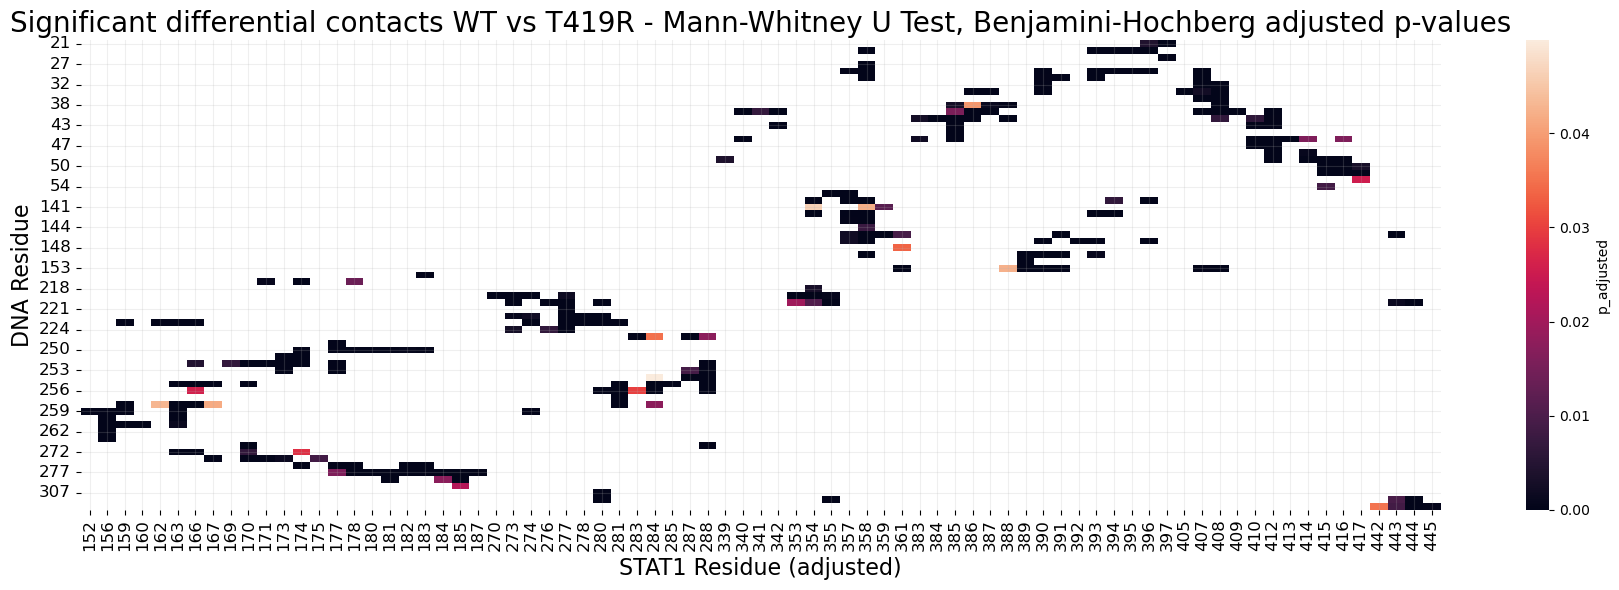

In [113]:
significant_pivot = pivotdf_count_avg_sig_bh(significant)

plt.figure(figsize=(18, 6))

# Chain A
sns.heatmap(significant_pivot, cmap='rocket', cbar_kws={'label': 'p_adjusted'})
plt.title('Significant differential contacts WT vs T419R - Mann-Whitney U Test, Benjamini-Hochberg adjusted p-values', fontsize=20)
plt.xlabel('STAT1 Residue (adjusted)', fontsize=16)
plt.ylabel('DNA Residue', fontsize=16)
plt.xticks(size=12)
plt.yticks(size=12)
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()